In [12]:
import pandas as pd
import seaborn as sns

titanic_data = sns.load_dataset("titanic")
titanic_data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [13]:
titanic_data.shape

(891, 15)

In [14]:
titanic_data.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [15]:
titanic_data.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [16]:
# step 1 --> removed the deck column
titanic_data.drop(columns = "deck", inplace= True)

In [17]:
titanic_data["age"].median()

28.0

In [18]:
titanic_data["age"].fillna(value= titanic_data["age"].median(), inplace= True)

C:\Users\da\AppData\Local\Temp\ipykernel_4532\2554995304.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_data["age"].fillna(value= titanic_data["age"].median(), inplace= True)


In [20]:
titanic_data["embark_town"].fillna(value = "unknown", inplace = True)

C:\Users\da\AppData\Local\Temp\ipykernel_4532\1441060414.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  titanic_data["embark_town"].fillna(value = "unknown", inplace = True)


In [25]:
titanic_data.isna().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [24]:
titanic_data["embarked"].fillna(value = "Unknown",inplace= True)

# UNIVARIATE ANALYSIS

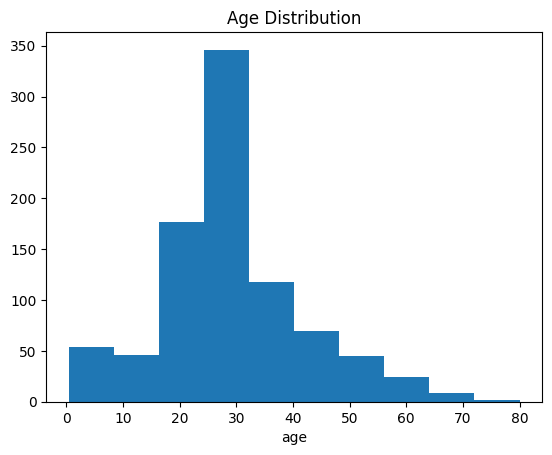

In [43]:
# Histogram --> Using Histogram represented the age distribution(one continous data)
import matplotlib.pyplot as plt

plt.hist(titanic_data["age"])
plt.title("Age Distribution")
plt.xlabel("age")
plt.show()

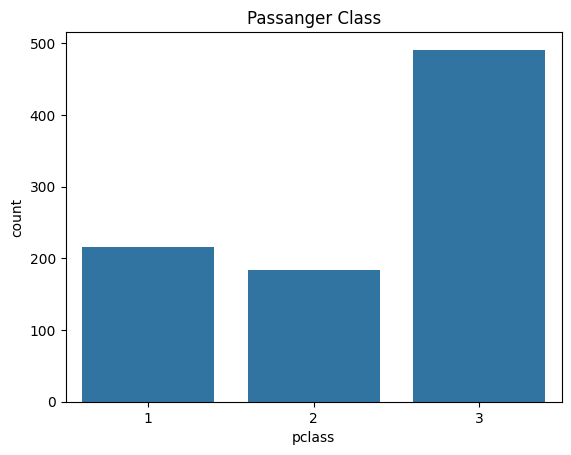

In [46]:
# Count plot

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data = titanic_data, x = "pclass")
plt.title("Passanger Class")
plt.show()

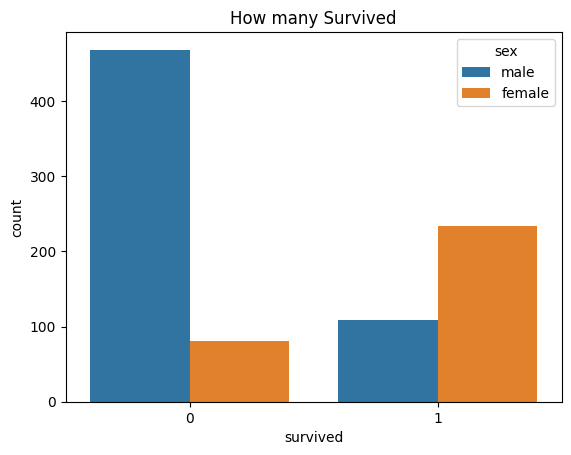

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data = titanic_data, x="survived", hue = "sex")
plt.title("How many Survived")
plt.show()

In [44]:
# Pie Chart

titanic_data["who"].value_counts()

who
man      537
woman    271
child     83
Name: count, dtype: int64

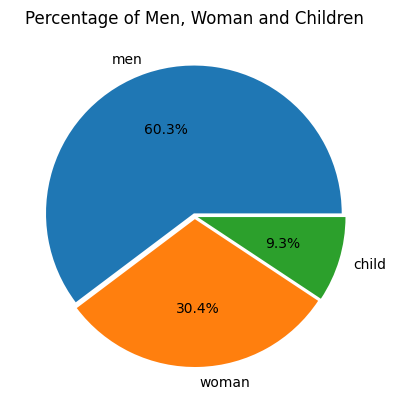

In [29]:
# PIE CHART

plt.pie(x = titanic_data["who"].value_counts(), labels=["men","woman","child"], explode=[0.02,0.02,0.02], autopct= "%1.1f%%")
plt.title("Percentage of Men, Woman and Children")
plt.show()

### Bivariate 

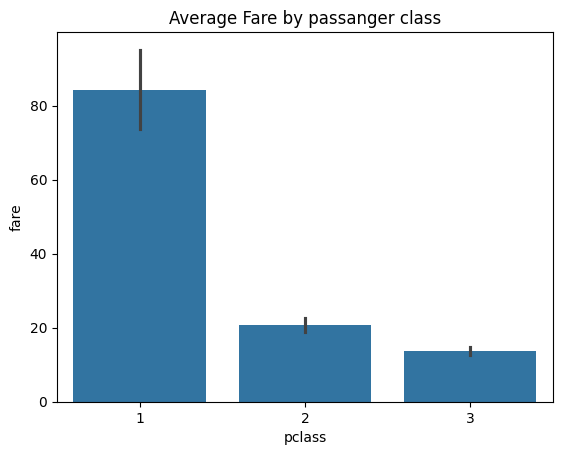

In [49]:
# barplot

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(data = titanic_data, x = "pclass", y = "fare")
plt.title("Average Fare by passanger class")
plt.show()

In [51]:
titanic_data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


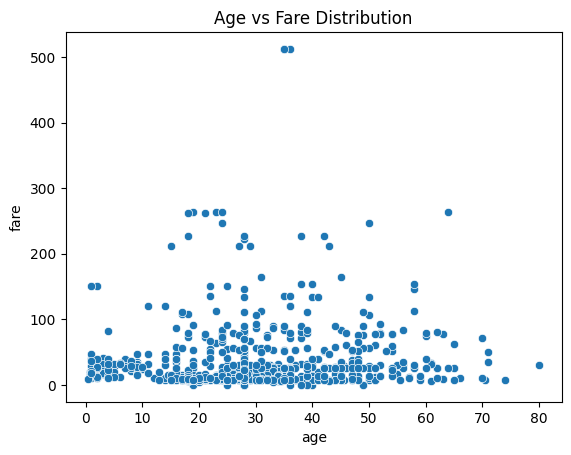

In [48]:
#scatter plot

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data = titanic_data, x = "age", y= "fare")
plt.title("Age vs Fare Distribution")
plt.show()

# MultiVariate

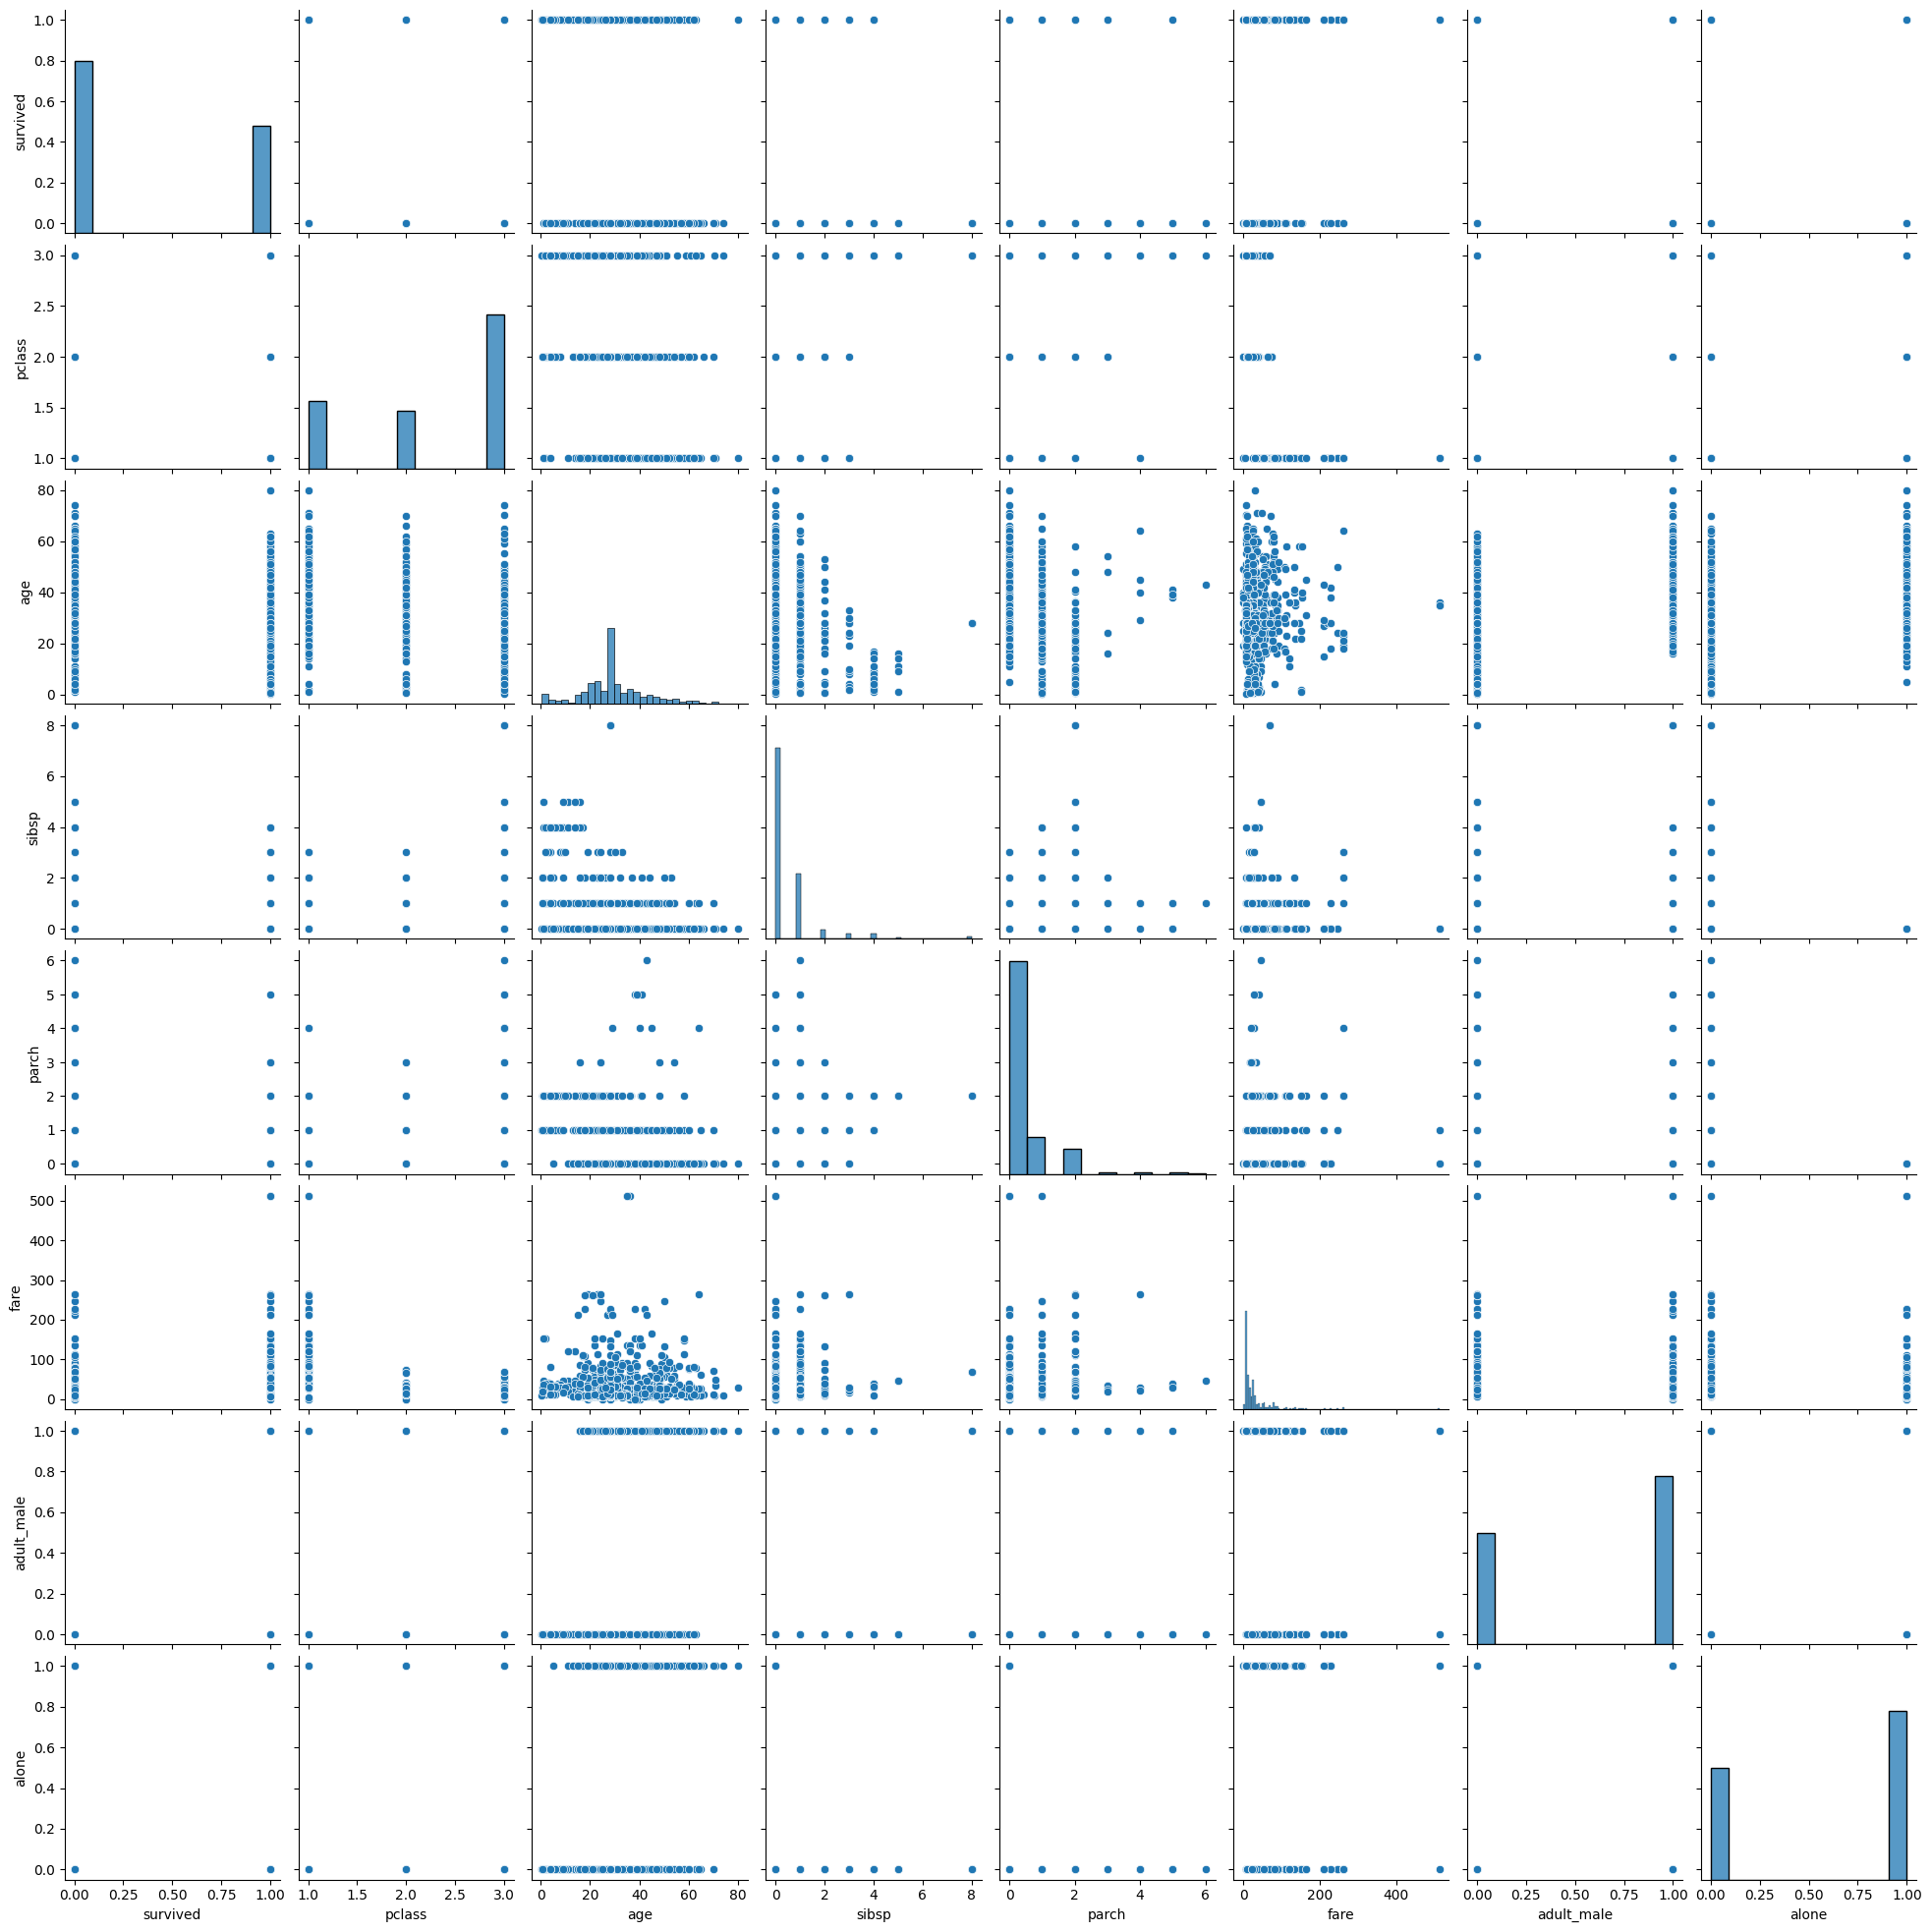

In [34]:
# pairplot

sns.pairplot(data = titanic_data)

<Axes: >

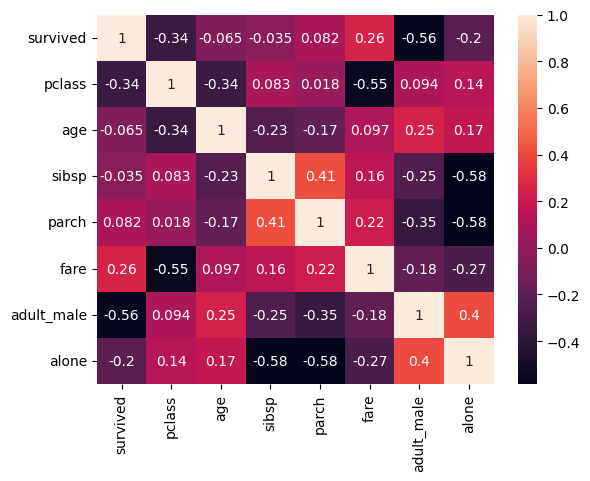

In [40]:
# heatmap

correlation = titanic_data.corr(numeric_only=True, method= "pearson")

sns.heatmap(data = correlation, annot = True)

In [42]:
"""
Correlation	Value	Interpretation
survived vs adult_male	-0.56	Strong negative correlation. Adult males were less likely to survive.
survived vs pclass	-0.34	Third-class passengers had lower survival rates.
survived vs fare	0.26	Passengers paying higher fares were more likely to survive.
survived vs alone	-0.20	People traveling alone had slightly lower survival rates.
survived vs age	-0.065	Almost no relationship between age and survival.
"""

'\nCorrelation\tValue\tInterpretation\nsurvived vs adult_male\t-0.56\tStrong negative correlation. Adult males were less likely to survive.\nsurvived vs pclass\t-0.34\tThird-class passengers had lower survival rates.\nsurvived vs fare\t0.26\tPassengers paying higher fares were more likely to survive.\nsurvived vs alone\t-0.20\tPeople traveling alone had slightly lower survival rates.\nsurvived vs age\t-0.065\tAlmost no relationship between age and survival.\n'